In [ ]:
# ===== Cell 1: Install & Imports =====
# No need to force an old version – Colab already has a good TensorFlow
!pip install -q importlib_resources
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ===== Cell 2: Download & Prepare Dataset =====
import tensorflow_datasets as tfds

IMG_SIZE = 128
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Automatic download
(ds_train, ds_val), ds_info = tfds.load(
    'cats_vs_dogs',
    split=['train[:80%]', 'train[80%:]'],
    shuffle_files=True,
    as_supervised=True,
    with_info=True
)

def preprocess(image, label):
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

train_ds = ds_train.map(preprocess, num_parallel_calls=AUTOTUNE)
train_ds = train_ds.cache().shuffle(1000).batch(BATCH_SIZE).prefetch(AUTOTUNE)

val_ds = ds_val.map(preprocess, num_parallel_calls=AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

class_names = ['cat', 'dog']
print("Classes:", class_names)
print("Number of training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Number of validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Dataset loaded successfully!")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.AZIGCL_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
Classes: ['cat', 'dog']
Number of training batches: 582
Number of validation batches: 146
Dataset loaded successfully!


In [ ]:
# ===== Cell 3: Build a Tiny model (MobileNetV2 style – very small) =====
def create_tiny_model(num_classes=2, img_size=128):
    base = keras.applications.MobileNetV2(
        input_shape=(img_size, img_size, 3),
        include_top=False,
        weights='imagenet',
        alpha=0.35          # makes it much smaller (TinyML friendly)
    )
    base.trainable = False   # freeze for fast training

    model = keras.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(64, activation='relu'),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

model = create_tiny_model(num_classes=2)
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

2019640/2019640 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_0.35_128            │ (None, 4, 4, 1280)     │       410,208 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 492,322 (1.88 MB)

 Trainable params: 82,114 (320.76 KB)

 Non-trainable params: 410,208 (1.56 MB)

In [ ]:
# ===== Cell 4: Train =====
EPOCHS = 8
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/8
582/582 ━━━━━━━━━━━━━━━━━━━━ 50s 64ms/step - accuracy: 0.9038 - loss: 0.2263 - val_accuracy: 0.9084 - val_loss: 0.2073
Epoch 2/8
582/582 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.9210 - loss: 0.1867 - val_accuracy: 0.9245 - val_loss: 0.1738
Epoch 3/8
582/582 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9314 - loss: 0.1639 - val_accuracy: 0.9213 - val_loss: 0.1824
Epoch 4/8
582/582 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.9363 - loss: 0.1515 - val_accuracy: 0.9297 - val_loss: 0.1667
Epoch 5/8
582/582 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.9411 - loss: 0.1398 - val_accuracy: 0.9278 - val_loss: 0.1702
Epoch 6/8
582/582 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.9481 - loss: 0.1268 - val_accuracy: 0.9280 - val_loss: 0.1749
Epoch 7/8
582/582 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9523 - loss: 0.1164 - val_accuracy: 0.9250 - val_loss: 0.1834
Epoch 8/8
582/582 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.9564 - loss: 0.1071 - val_accu

146/146 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.9288 - loss: 0.1769
Validation Accuracy: 0.9288


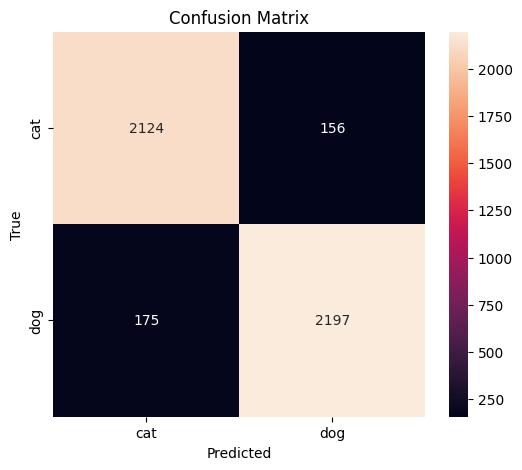

              precision    recall  f1-score   support

         cat       0.92      0.93      0.93      2280
         dog       0.93      0.93      0.93      2372

    accuracy                           0.93      4652
   macro avg       0.93      0.93      0.93      4652
weighted avg       0.93      0.93      0.93      4652



In [ ]:
# ===== Cell 5: Evaluate + Confusion Matrix =====
loss, acc = model.evaluate(val_ds)
print(f"Validation Accuracy: {acc:.4f}")

# Predictions for confusion matrix
y_true, y_pred = [], []
for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))

In [ ]:
# ===== Cell 6: Convert to TensorFlow Lite (TinyML ready) =====
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]  # quantization
tflite_model = converter.convert()

with open('animal_detection_tiny.tflite', 'wb') as f:
    f.write(tflite_model)

print(f"TFLite model size: {os.path.getsize('animal_detection_tiny.tflite') / 1024:.1f} KB")

Saved artifact at '/tmp/tmpel_n49gk'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  134444807216144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134444766842320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134444766839056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134444766842512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134444766841936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134444766842704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134444766839824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134444766843472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134444766839632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134444766842128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1344447668

In [ ]:
# ===== Cell 7 (Optional): Upload to Google Cloud Storage =====
from google.colab import auth
auth.authenticate_user()

!gsutil cp animal_detection_tiny.tflite gs://YOUR-BUCKET-NAME/models/
!gsutil cp -r /content/ gs://YOUR-BUCKET-NAME/tinyml-animal-detection/   # optional full backup

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
Copying file://animal_detection_tiny.tflite [Content-Type=application/octet-stream]...
BadRequestException: 400 Invalid bucket name: 'YOUR-BUCKET-NAME'
Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
Copying file:///content/animal_detection_tiny.tflite [Content-Type=application/octet-stream]...
BadRequestException: 400 Invalid bucket name: 'YOUR-BUCKET-NAME'
